# App Review Sentiment Classification
**Name:** Abdul Moiz Abbasi  

**Reg. No:** FA23-BAI-001  

## **Lab 06**

This notebook builds a TF-IDF + Logistic Regression pipeline to classify app reviews as *negative*, *neutral* or *positive*, then evaluates it, inspects its errors, tests class balancing, and applies it to new customer feedback.

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 200)

## Dataset creation (synthetic app reviews)

In [2]:
pos_core = ["I love this app", "works perfectly on my phone", "the interface is clean and easy to use",
            "it saves me so much time every day", "customer support fixed my issue quickly",
            "the latest update made everything faster", "best app I have used for this purpose",
            "setup took two minutes and it just works", "really helpful features and great design",
            "syncs across my devices without any problem", "super smooth and reliable", "totally worth the price"]
neg_core = ["the app crashes every time I open it", "it keeps freezing and I lose my data",
            "login never works and I am locked out", "terrible battery drain since the update",
            "customer support never replied to my emails", "I was charged twice and cannot get a refund",
            "the app is painfully slow and full of bugs", "notifications are broken and ads are everywhere",
            "sync fails constantly and my files disappear", "complete waste of money", 
            "it won't load after the latest update", "the worst app I have ever installed"]
neu_core = ["it does what it says, nothing more", "the app is okay for basic use", "average app with a few useful features",
            "some things work well and others do not", "it is fine but nothing special", 
            "decent app, still missing a few options", "works most of the time", "the design is plain but functional",
            "not bad, not great either", "does the job for now", "I use it occasionally and it is acceptable",
            "pricing is about what I expected"]
pos_open = ["Great app.", "Five stars.", "Really happy with it.", "Very impressed.", "Awesome update.", ""]
neg_open = ["Very disappointed.", "One star.", "Do not download.", "So frustrating.", "Awful experience.", ""]
neu_open = ["Honest review:", "Mixed feelings.", "After a week of use:", "Quick thoughts:", "Three stars.", ""]
pos_close = ["Highly recommend!", "Will keep using it.", "Thank you developers.", "Keep up the good work.", ""]
neg_close = ["Please fix this.", "Want my money back.", "Uninstalling now.", "Fix it or I am leaving.", ""]
neu_close = ["Could be better.", "Might change my rating later.", "Let us see what the next update brings.", ""]

pools = {"positive": (pos_open, pos_core, pos_close),
         "negative": (neg_open, neg_core, neg_close),
         "neutral":  (neu_open, neu_core, neu_close)}

def make_review(label, rng):
    o, c, cl = pools[label]
    parts = [rng.choice(o), rng.choice(c).capitalize() + ".", rng.choice(cl)]
    # ~18%: mixed-sentiment review (borrows a clause from another class) -> creates ambiguity
    if rng.random() < 0.18:
        other = rng.choice([l for l in pools if l != label])
        parts.insert(rng.randint(1, 2), rng.choice(pools[other][1]).capitalize() + ", but")
    text = " ".join(p for p in parts if p).replace(", but .", ", but")
    # light typo noise
    if rng.random() < 0.10:
        text = text.replace("the", "teh", 1)
    return text

rng = random.Random(SEED)
counts = {"positive": 1000, "neutral": 450, "negative": 250}   # imbalanced on purpose
rows = [(make_review(l, rng), l) for l, n in counts.items() for _ in range(n)]
df = pd.DataFrame(rows, columns=["text", "label"]).sample(frac=1, random_state=SEED).reset_index(drop=True)

# ~4% label noise (human labelling errors)
noisy = df.sample(frac=0.04, random_state=SEED).index
df.loc[noisy, "label"] = [random.Random(i).choice([l for l in counts if l != df.loc[i, "label"]]) for i in noisy]

df.to_csv("app_reviews.csv", index=False)
print(df.shape); df.head(8)

(1700, 2)


,text,label
0,Very disappointed. It keeps freezing and i lose my data.,negative
1,Great app. Syncs across my devices without any problem. Will keep using it.,positive
2,"Really happy with it. Customer support fixed my issue quickly. It keeps freezing and i lose my data, but W...",positive
3,Awesome update. The interface is clean and easy to use. Thank you developers.,positive
4,"Mixed feelings. Not bad, not great either.",neutral
5,"Decent app, still missing a few options. Might change my rating later.",neutral
6,Quick thoughts: It is fine but nothing special. Let us see what the next update brings.,neutral
7,Very impressed. Works perfectly on my phone. Thank you developers.,positive


## Activity 1: TF-IDF + Logistic Regression pipeline

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    df["text"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED)

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)

print(f"Train size: {len(X_train)} | Test size: {len(X_test)}\n")
print(f"Accuracy          : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision (macro) : {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall    (macro) : {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1-score  (macro) : {f1_score(y_test, y_pred, average='macro'):.4f}\n")
print(classification_report(y_test, y_pred, digits=4))

Train size: 1360 | Test size: 340

Accuracy          : 0.9618
Precision (macro) : 0.9716
Recall    (macro) : 0.9443
F1-score  (macro) : 0.9570

              precision    recall  f1-score   support

    negative     0.9804    0.9259    0.9524        54
     neutral     0.9881    0.9121    0.9486        91
    positive     0.9463    0.9949    0.9700       195

    accuracy                         0.9618       340
   macro avg     0.9716    0.9443    0.9570       340
weighted avg     0.9629    0.9618    0.9615       340



**Interpretation:** The model reaches about 96% accuracy on the held-out 20% test split (340 reviews, stratified so class proportions match the full data). Macro precision, recall and F1 are all in the 94-97% range, and the negative class scores precision 0.98 / recall 0.93 / F1 0.95. These scores are high partly because the synthetic reviews use a limited vocabulary, so real-world data would likely score lower (see Activity 5).

## Activity 2: Confusion matrix

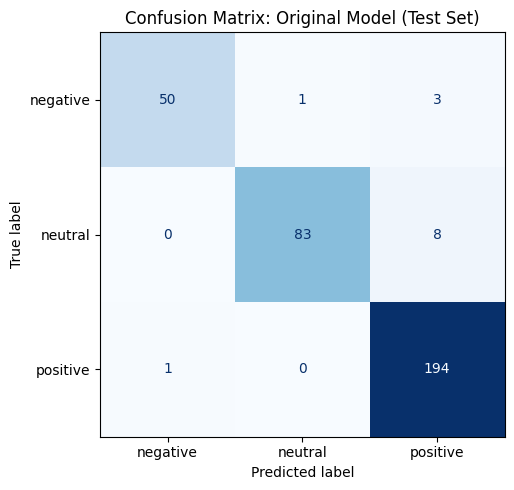

               pred_negative  pred_neutral  pred_positive
true_negative             50             1              3
true_neutral               0            83              8
true_positive              1             0            194


In [4]:
labels = ["negative", "neutral", "positive"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix: Original Model (Test Set)")
plt.tight_layout(); plt.show()
print(pd.DataFrame(cm, index=[f"true_{l}" for l in labels], columns=[f"pred_{l}" for l in labels]))

**What the matrix shows:** The model struggles most with the **neutral** class: it has the lowest recall (0.91), and 8 of its 91 neutral test reviews were pushed into *positive*. This happens because neutral reviews often contain mildly positive phrases ("decent", "works", "fine") and mixed-sentiment reviews borrow positive clauses, so they sit close to the positive decision boundary. The negative class is the second weakest, with 4 of 54 missed (3 predicted positive, 1 neutral), while the positive class is almost never missed (194 of 195). Because positive is the largest class, the model also leans toward predicting it when it is unsure.

## Activity 3: Most confident misclassifications

In [5]:
proba = pipe.predict_proba(X_test)
pred_prob = proba.max(axis=1)           # probability of the predicted class
mask = (y_pred != y_test.values)

errors = pd.DataFrame({
    "text": X_test.values[mask],
    "true_label": y_test.values[mask],
    "predicted_label": y_pred[mask],
    "predicted_probability": pred_prob[mask],
}).sort_values("predicted_probability", ascending=False).reset_index(drop=True)

print(f"Total misclassified: {len(errors)} of {len(X_test)}\n")
errors.head(5)

Total misclassified: 13 of 340



,text,true_label,predicted_label,predicted_probability
0,Very impressed. Customer support fixed my issue quickly. Will keep using it.,neutral,positive,0.976538
1,Customer support fixed my issue quickly. Keep up the good work.,neutral,positive,0.951219
2,Customer support fixed my issue quickly. Thank you developers.,negative,positive,0.947422
3,Five stars. The interface is clean and easy to use. Thank you developers.,neutral,positive,0.924810
4,Mixed feelings. Does the job for now. Might change my rating later.,negative,neutral,0.915705


**Observation:** The model's most confident mistakes are mostly reviews whose wording is clearly positive (e.g. "customer support fixed my issue quickly", "thank you developers") but whose recorded label is neutral or negative. These are largely the noisy / mixed-sentiment examples built into the dataset, so the "error" is often an ambiguous or arguably mislabelled review rather than a clear model failure. A high predicted probability therefore does not guarantee correctness, and these are the reviews worth manually checking for label quality.

## Activity 4: Class distribution and class balancing

Class counts:
label
positive    975
neutral     453
negative    272
Name: count, dtype: int64

Class proportions:
label
positive    0.574
neutral     0.266
negative    0.160
Name: proportion, dtype: float64


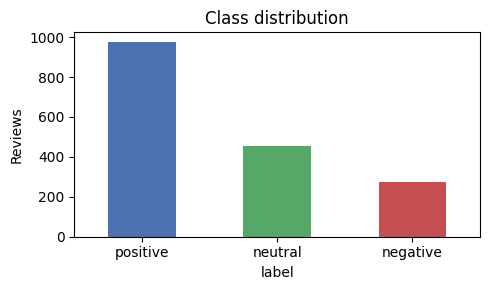

In [6]:
print("Class counts:"); print(df["label"].value_counts()); print()
print("Class proportions:"); print(df["label"].value_counts(normalize=True).round(3))

df["label"].value_counts().plot(kind="bar", color=["#4C72B0", "#55A868", "#C44E52"], figsize=(5, 3))
plt.title("Class distribution"); plt.ylabel("Reviews"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [7]:
pipe_bal = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, lowercase=True)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])
pipe_bal.fit(X_train, y_train)
y_pred_bal = pipe_bal.predict(X_test)

def neg_metrics(y_true, y_hat):
    return {"precision": precision_score(y_true, y_hat, labels=["negative"], average=None)[0],
            "recall":    recall_score(y_true, y_hat, labels=["negative"], average=None)[0],
            "f1":        f1_score(y_true, y_hat, labels=["negative"], average=None)[0]}

comparison = pd.DataFrame({"Original (Act. 1)": neg_metrics(y_test, y_pred),
                           "Balanced (class_weight)": neg_metrics(y_test, y_pred_bal)}).round(4)
comparison["Change"] = (comparison["Balanced (class_weight)"] - comparison["Original (Act. 1)"]).round(4)
print("Negative-class metrics, side by side:\n"); comparison

Negative-class metrics, side by side:



,Original (Act. 1),Balanced (class_weight),Change
precision,0.9804,0.9623,-0.0181
recall,0.9259,0.9444,0.0185
f1,0.9524,0.9533,0.0009


In [8]:
print("Overall accuracy -> original: %.4f | balanced: %.4f" %
      (accuracy_score(y_test, y_pred), accuracy_score(y_test, y_pred_bal)))

Overall accuracy -> original: 0.9618 | balanced: 0.9618


**Observation:** The dataset is imbalanced: positive is 57%, neutral 27% and negative only 16%. Using `class_weight='balanced'` raised negative-class recall from 0.926 to 0.944 (one extra negative review caught) while precision fell from 0.980 to 0.962, leaving F1 essentially unchanged (0.952 vs 0.953). Overall accuracy is identical. The effect is small because the imbalance is moderate and the test set contains only 54 negatives, so a difference of one review moves the metrics by about 2 points. Balancing is still a sensible trade-off for this use case, since missing a negative review is usually costlier than a false alarm.

## Activity 5: Auto-flagging negative reviews on new, unseen feedback

In [9]:
new_feedback = [
    "Love the new dashboard, it loads instantly and looks great.",
    "The app crashed three times today and I lost all my work. Unacceptable.",
    "It's okay. Does the basics but I wish it had dark mode.",
    "I was billed twice this month and support has ignored my emails.",
    "Fantastic customer service, they solved my problem in minutes!",
    "Can't log in since the update. Please fix this ASAP.",
    "Average experience, nothing to complain about but nothing exciting either.",
    "Super helpful app, I use it every single day.",
    "Notifications are completely broken and the ads are getting out of hand.",
    "Great idea, but it freezes constantly and drains my battery.",
    "Works fine for me, though the price is a bit high.",
    "Oh wonderful, another update that deletes my files. Thanks a lot.",
    "Really smooth and reliable, easily worth the subscription.",
    "Sync keeps failing and nobody from support has answered me in a week.",
    "Pretty decent app overall, a few minor bugs here and there.",
]
new_df = pd.DataFrame({"text": new_feedback})
new_df["predicted_label"] = pipe.predict(new_df["text"])
neg_idx = list(pipe.classes_).index("negative")
new_df["P(negative)"] = pipe.predict_proba(new_df["text"])[:, neg_idx].round(3)
new_df["flagged_negative"] = new_df["predicted_label"] == "negative"
new_df

,text,predicted_label,P(negative),flagged_negative
0,"Love the new dashboard, it loads instantly and looks great.",positive,0.099,False
1,The app crashed three times today and I lost all my work. Unacceptable.,positive,0.205,False
2,It's okay. Does the basics but I wish it had dark mode.,neutral,0.106,False
3,I was billed twice this month and support has ignored my emails.,negative,0.518,True
4,"Fantastic customer service, they solved my problem in minutes!",positive,0.186,False
5,Can't log in since the update. Please fix this ASAP.,negative,0.846,True
6,"Average experience, nothing to complain about but nothing exciting either.",neutral,0.214,False
7,"Super helpful app, I use it every single day.",positive,0.107,False
8,Notifications are completely broken and the ads are getting out of hand.,negative,0.586,True
9,"Great idea, but it freezes constantly and drains my battery.",positive,0.327,False


In [10]:
flagged = new_df[new_df["flagged_negative"]]
print(f"{len(flagged)} of {len(new_df)} snippets flagged as NEGATIVE for the support team:\n")
for i, r in flagged.iterrows():
    print(f"  [{i+1:>2}] (P(neg)={r['P(negative)']:.2f}) {r['text']}")

3 of 15 snippets flagged as NEGATIVE for the support team:

  [ 4] (P(neg)=0.52) I was billed twice this month and support has ignored my emails.
  [ 6] (P(neg)=0.85) Can't log in since the update. Please fix this ASAP.
  [ 9] (P(neg)=0.59) Notifications are completely broken and the ads are getting out of hand.


### Recommendation to the business

The model flagged 3 of the 15 new snippets, and all 3 were genuinely negative, so a flagged review can be trusted (precision on test data: 0.98). However, by my own reading 7 of the 15 snippets are actually negative, so the model missed 4 of them (about 43% recall on this sample), compared with 93% recall on the original test split. The misses were reviews with positive-sounding words next to complaints ("Great idea, but it freezes..."), sarcasm ("Oh wonderful, another update that deletes my files"), and complaints phrased in wording the model had not seen in training ("crashed three times", "sync keeps failing"). We recommend using the auto-flagging only as a first-pass priority queue, not as a filter: flagged reviews go to support first, but unflagged reviews should still be reviewed, and the model should be retrained on the business's own real, labelled reviews (and a lower flagging threshold, e.g. P(negative) > 0.30, considered) before relying on it more heavily.